# DQN (Deep Q-Network): blood delivery drone

DQN learns a **Q-value** for every action: how much reward the drone expects to get if it takes that action now and then keeps playing well. The drone picks the action with the highest Q-value. It stores old experience in a **replay buffer** and learns from random batches of it. A second copy of the network, the **target network**, keeps the learning stable (this is the Double DQN version, where the online network chooses the next action and the target network scores it). To explore, it takes a random action with probability **epsilon**, and epsilon gets smaller every episode.

The drone must fly from the blood bank to the hospital, deliver the blood package and fly back, while avoiding towers, storms and an empty battery. Below we train DQN for **500 episodes** with 10 different hyperparameter settings (one parameter changed at a time: learning rate, gamma, batch size, epsilon decay and buffer size) and compare the results.

## 1. Setup

In [1]:
import os
import sys
import random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import deque

# Run from the project root so that `environment/` can be imported.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from environment.custom_env import BloodDroneEnv, MASK_START, mask_scores

env = BloodDroneEnv()
STATE_SIZE = env.observation_space.shape[0]   # 43 numbers describe the drone and its surroundings
NUM_ACTIONS = env.action_space.n              # 9 actions
print("State size:", STATE_SIZE, "| Actions:", NUM_ACTIONS)


State size: 43 | Actions: 9


## 2. Helper functions

`make_net` builds a small neural network.

In [2]:
EPISODES = 500          # training episodes for every experiment
REWARD_SCALE = 0.1      # smaller rewards for training only (helps stability)


def make_net(inputs, hidden, outputs):
    """A small neural network: inputs -> hidden layers -> one score per action."""
    layers, size = [], inputs
    for h in hidden:
        layers += [nn.Linear(size, h), nn.ReLU()]
        size = h
    layers.append(nn.Linear(size, outputs))
    return nn.Sequential(*layers)


## 3. The DQN agent

`train_dqn` trains one agent for 500 episodes and returns the reward of every episode and the loss values.

In [3]:
def train_dqn(config, episodes=EPISODES):
    """Train one DQN agent. Returns the reward of every episode and the loss values."""
    random.seed(0); np.random.seed(0); torch.manual_seed(0)
    # practice=0.8: the same training setting as training/dqn_training.py
    env = BloodDroneEnv(practice=0.8)

    online_net = make_net(STATE_SIZE, (64, 64), NUM_ACTIONS)
    target_net = make_net(STATE_SIZE, (64, 64), NUM_ACTIONS)
    target_net.load_state_dict(online_net.state_dict())
    optimizer = optim.Adam(online_net.parameters(), lr=config["lr"])

    memory = deque(maxlen=config["buffer_size"])   # replay buffer
    epsilon, steps = 1.0, 0
    rewards, losses = [], []

    for episode in range(episodes):
        state, _ = env.reset()
        done, total = False, 0.0

        while not done:
            # Explore at random with chance epsilon, otherwise pick the best possible action.
            if random.random() < epsilon:
                action = random.choice(list(np.flatnonzero(state[MASK_START:MASK_START + 9])))
            else:
                with torch.no_grad():
                    obs = torch.tensor(state)
                    action = int(mask_scores(online_net(obs), obs).argmax())

            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            memory.append((state, action, reward * REWARD_SCALE, next_state, float(terminated)))
            state, total, steps = next_state, total + reward, steps + 1

            # Learn from a random batch of old experience.
            if len(memory) >= config["batch_size"]:
                batch = random.sample(memory, config["batch_size"])
                s, a, r, s2, d = zip(*batch)
                s = torch.tensor(np.array(s), dtype=torch.float32)
                s2 = torch.tensor(np.array(s2), dtype=torch.float32)
                a = torch.tensor(a)
                r = torch.tensor(r, dtype=torch.float32)
                d = torch.tensor(d)

                q = online_net(s).gather(1, a.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    # Double DQN: the online network picks the next action, the target network scores it.
                    best = mask_scores(online_net(s2), s2).argmax(1, keepdim=True)
                    best_next = mask_scores(target_net(s2), s2).gather(1, best).squeeze(1)
                target = r + config["gamma"] * best_next * (1 - d)

                loss = F.smooth_l1_loss(q, target)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                losses.append(loss.item())

            # Copy the online network into the target network now and then.
            if steps % 250 == 0:
                target_net.load_state_dict(online_net.state_dict())

        epsilon = max(0.05, epsilon * config["eps_decay"])   # explore a little less each episode
        rewards.append(total)

    return rewards, losses


## 4. The 10 experiments

Experiment 1 is the baseline. In each of the other nine experiments only one hyperparameter is changed.

In [4]:
dqn_configs = [
    {"name": "DQN-1", "lr": 0.001, "gamma": 0.99, "batch_size": 64, "eps_decay": 0.995, "buffer_size": 10000},
    {"name": "DQN-2", "lr": 0.0003, "gamma": 0.99, "batch_size": 64, "eps_decay": 0.995, "buffer_size": 10000},
    {"name": "DQN-3", "lr": 0.0001, "gamma": 0.99, "batch_size": 64, "eps_decay": 0.995, "buffer_size": 10000},
    {"name": "DQN-4", "lr": 0.001, "gamma": 0.95, "batch_size": 64, "eps_decay": 0.995, "buffer_size": 10000},
    {"name": "DQN-5", "lr": 0.001, "gamma": 0.999, "batch_size": 64, "eps_decay": 0.995, "buffer_size": 10000},
    {"name": "DQN-6", "lr": 0.001, "gamma": 0.99, "batch_size": 32, "eps_decay": 0.995, "buffer_size": 10000},
    {"name": "DQN-7", "lr": 0.001, "gamma": 0.99, "batch_size": 128, "eps_decay": 0.995, "buffer_size": 10000},
    {"name": "DQN-8", "lr": 0.001, "gamma": 0.99, "batch_size": 64, "eps_decay": 0.99, "buffer_size": 10000},
    {"name": "DQN-9", "lr": 0.001, "gamma": 0.99, "batch_size": 64, "eps_decay": 0.999, "buffer_size": 10000},
    {"name": "DQN-10", "lr": 0.001, "gamma": 0.99, "batch_size": 64, "eps_decay": 0.995, "buffer_size": 20000},
]

## 5. Run the experiments

In [5]:
results = []      # one row per experiment
curves = {}       # reward of every episode, for the plots

for config in dqn_configs:
    rewards, losses = train_dqn(config)
    curves[config["name"]] = rewards
    results.append({
        "experiment": config["name"],
        "average reward": round(float(np.mean(rewards)), 1),
        "last 100": round(float(np.mean(rewards[-100:])), 1),
        "loss": round(float(np.mean(losses)), 3),
    })
    print(config["name"], "| average:", results[-1]["average reward"], "| last 100:", results[-1]["last 100"], "| loss:", results[-1]["loss"])

DQN-1 | average: -71.6 | last 100: -62.5 | loss: 0.134


DQN-2 | average: -75.8 | last 100: -71.7 | loss: 0.108


DQN-3 | average: -66.2 | last 100: -60.5 | loss: 0.136


DQN-4 | average: -69.3 | last 100: -48.3 | loss: 0.092


DQN-5 | average: -76.2 | last 100: -73.7 | loss: 0.113


DQN-6 | average: -72.7 | last 100: -61.5 | loss: 0.113


DQN-7 | average: -68.5 | last 100: -52.5 | loss: 0.104


DQN-8 | average: -76.5 | last 100: -55.6 | loss: 0.08


DQN-9 | average: -105.2 | last 100: -103.8 | loss: 0.178


DQN-10 | average: -75.7 | last 100: -61.1 | loss: 0.114


## 6. Results

In [6]:
print(f"{'experiment':<14}{'average reward':>16}{'last 100':>12}{'loss':>10}")
for row in results:
    print(f"{row['experiment']:<14}{row['average reward']:>16}{row['last 100']:>12}{row['loss']:>10}")

experiment      average reward    last 100      loss
DQN-1                    -71.6       -62.5     0.134
DQN-2                    -75.8       -71.7     0.108
DQN-3                    -66.2       -60.5     0.136
DQN-4                    -69.3       -48.3     0.092
DQN-5                    -76.2       -73.7     0.113
DQN-6                    -72.7       -61.5     0.113
DQN-7                    -68.5       -52.5     0.104
DQN-8                    -76.5       -55.6      0.08
DQN-9                   -105.2      -103.8     0.178
DQN-10                   -75.7       -61.1     0.114


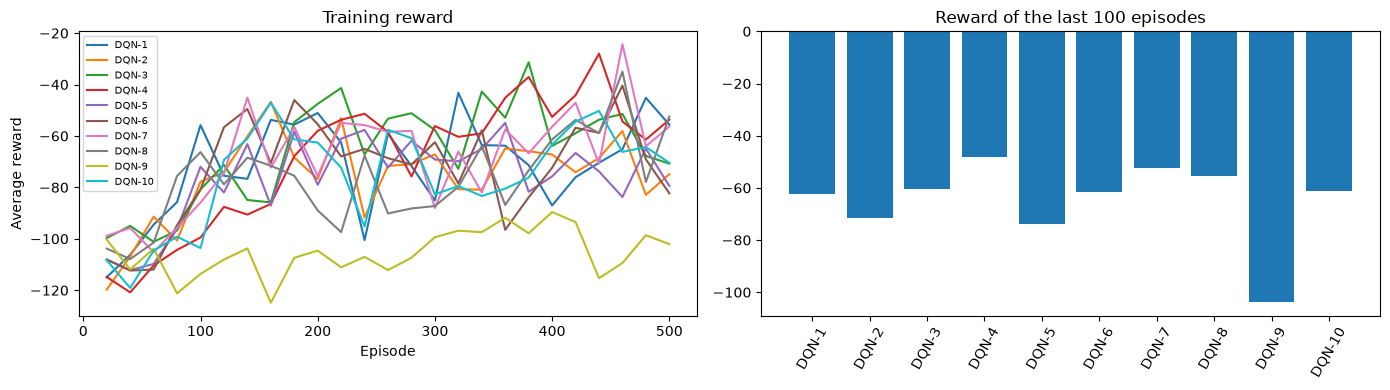

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# learning curves (average of every 20 episodes)
for name, rewards in curves.items():
    smooth = [np.mean(rewards[i:i + 20]) for i in range(0, len(rewards), 20)]
    axes[0].plot(range(20, len(rewards) + 1, 20), smooth, label=name)
axes[0].set_title("Training reward")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Average reward")
axes[0].legend(fontsize=7)

# reward of the last 100 episodes of every experiment (what the agent learned)
axes[1].bar([row["experiment"] for row in results], [row["last 100"] for row in results])
axes[1].set_title("Reward of the last 100 episodes")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 7. Best hyperparameters

The best experiment is the one with the highest average reward in its last 100 episodes, because that shows what the agent has learned (the early episodes are mostly random exploration). These values are the ones to use in `training/dqn_training.py`.

In [8]:
# the best experiment has the highest reward in its last 100 episodes (smaller loss breaks a tie)
best = sorted(results, key=lambda row: (-row["last 100"], row["loss"]))[0]
best_config = next(c for c in dqn_configs if c["name"] == best["experiment"])

print("Best experiment:", best["experiment"])
print("Last 100 episodes:", best["last 100"], "| average:", best["average reward"], "| loss:", best["loss"])
print("Best hyperparameters:")
for key, value in best_config.items():
    if key != "name":
        print("  ", key, "=", value)

Best experiment: DQN-4
Last 100 episodes: -48.3 | average: -69.3 | loss: 0.092
Best hyperparameters:
   lr = 0.001
   gamma = 0.95
   batch_size = 64
   eps_decay = 0.995
   buffer_size = 10000
